# EMQA_L6_solar_growth

**Installed solar capacity at year end in Romania, Bulgaria and Hungary (2019-2025, ENTSO-E) and yearly Romanian solar output in TWh (2019 to 2026-10-31, 2026 = Jan-Oct). Prints the growth factor of Romanian capacity, the like-for-like Jan-cut-off output of the last two years and the solar share of load.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_solar_growth/EMQA_L6_solar_growth.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Installed capacity is read at year end; energy = sum over intervals of mean MW x interval length (h).

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def load_gen(c):
    """Generation and load of country c (ro, bg, hu), MW, native resolution, CET/CEST index."""
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ)
    return g


def on_price_grid(g):
    """Generation columns on the price grid: hourly mean for hourly prices; 15-min value for 15-min prices
    (the hourly value is repeated when the source is hourly, as for Bulgaria)."""
    gg = g.drop(columns=['mtu_minutes']).copy()
    out = gg.resample('1h').mean().reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX['mtu_minutes'] == 15
    if (g['mtu_minutes'] == 15).loc[g.index >= MTU15].all():
        out.loc[q15] = gg.resample('15min').mean().reindex(PX.index[q15]).values
    return out


GN = {c.upper(): load_gen(c) for c in ('ro',)}
GR = {z: on_price_grid(GN[z]) for z in GN}
print({z: (str(g.index.min())[:10], str(g.index.max())[:10]) for z, g in GN.items()})

{'RO': ('2018-12-30', '2026-11-04')}


In [6]:
CAP = pd.read_csv(DATA + 'installed_capacity_yearly.csv')
cap = CAP[CAP['type'].str.startswith('Solar')]
solar_gw = {z: {int(r.year): fl(r.gw, 2) for r in cap[cap.country == z].itertuples()} for z in ('RO', 'BG', 'HU')}
last_year = int(CAP['year'].max())

ro, dur = GR['RO'], PX['dur']
twh = {y: {c: fl((ro[c][LOC_YEAR == y] * dur[LOC_YEAR == y]).sum() / 1e6, 2) for c in ('solar', 'load')} for y in YEARS}
lfl = {}                                              # like-for-like: January to the cut-off month
for y in (Y - 1, Y):
    m = (LOC_YEAR == y) & (PX.index.month <= END.month)
    lfl[y] = fl((ro['solar'][m] * dur[m]).sum() / 1e6, 2)

show_numbers({'cap.last_year': last_year,
              'cap.solar_ro_x': fl(solar_gw['RO'][last_year] / solar_gw['RO'][2019], 1),
              f'cap.solar.BG.{last_year}': solar_gw['BG'][last_year],
              f'cap.solar.HU.{last_year}': solar_gw['HU'][last_year],
              f'twh_lfl.{Y - 1}.solar': lfl[Y - 1], f'twh_lfl.{Y}.solar': lfl[Y],
              'twh.solar_share_load_2019': fl(twh[2019]['solar'] / twh[2019]['load'] * 100, 1),
              'twh.solar_share_load_ytd': fl(twh[Y]['solar'] / twh[Y]['load'] * 100, 1)})

cap.last_year                      2025
cap.solar_ro_x                     2.4
cap.solar.BG.2025                  7.16
cap.solar.HU.2025                  8.97
twh_lfl.2025.solar                 2.53
twh_lfl.2026.solar                 4.32
twh.solar_share_load_2019          2.3
twh.solar_share_load_ytd           10.2


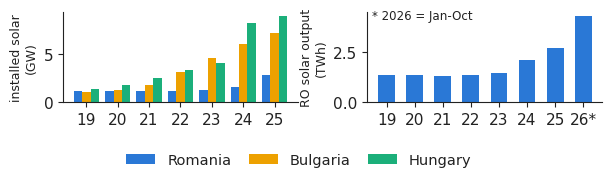

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 1.85))
cy = list(range(2019, last_year + 1))
wdt = 0.27
for i, z in enumerate(('RO', 'BG', 'HU')):
    axs[0].bar(np.array(cy) + (i - 1) * wdt, [solar_gw[z][y] for y in cy], width=wdt, color=PAL[z], label=ZN[z])
axs[0].set_ylabel('installed solar\n(GW)', fontsize=9)
axs[0].set_xticks(cy)
axs[0].set_xticklabels([str(y)[2:] for y in cy])
axs[1].bar(range(len(YEARS)), [twh[y]['solar'] for y in YEARS], color=PAL['RO'], width=0.6)
axs[1].set_xticks(range(len(YEARS)))
axs[1].set_xticklabels([str(y)[2:] + ('*' if y == Y else '') for y in YEARS])
axs[1].set_ylabel('RO solar output\n(TWh)', fontsize=9)
axs[1].text(0.02, 0.92, YTD, transform=axs[1].transAxes, fontsize=8.5)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('solar_growth.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()